# CPU と GPU の比較

CPU と GPU の計算・転送・学習時間を比較しましょう。メモリ容量も確認します。

GPU の性能比較には CUDA 対応 GPU が必要です。

In [1]:
!pip install -q torch  # 行列演算とニューラルネットワーク
!pip install -q numpy  # 計測値の集計
!pip install -q torchvision  # MNIST の取得
!pip install -q tqdm  # 学習の進捗と経過時間


In [2]:
import os

import torch

torch.set_num_threads(min(4, os.cpu_count() or 1))
# 一部の GPU で使用可能な数値精度である TF32 を無効にし、CPU と比較する数値精度を揃えます。
torch.backends.cuda.matmul.allow_tf32 = False
torch.backends.cudnn.allow_tf32 = False
devices = [torch.device("cpu")]
if torch.cuda.is_available():
    devices.append(torch.device("cuda"))
print("PyTorch:", torch.__version__, "/ CPU threads:", torch.get_num_threads())
print("測定対象:", [str(device) for device in devices])
if len(devices) == 1:
    print("GPU は未測定です。Colab のランタイムを GPU に切り替えると比較できます。")

PyTorch: 2.11.0+cu130 / CPU threads: 4
測定対象: ['cpu', 'cuda']


## メモリ容量

CPU と GPU が一度に保持できるデータ量を確認します。CPU はシステムの物理メモリ、GPU はデバイスメモリを表示します。

In [3]:
if hasattr(os, "sysconf"):
    physical_gib = os.sysconf("SC_PAGE_SIZE") * os.sysconf("SC_PHYS_PAGES") / 2**30
    print(f"システム物理メモリ: {physical_gib:.1f} GiB")
if torch.cuda.is_available():
    properties = torch.cuda.get_device_properties(0)
    print(
        f"GPU: {properties.name} / デバイスメモリ: {properties.total_memory / 2**30:.1f} GiB"
    )

システム物理メモリ: 53.0 GiB
GPU: NVIDIA L4 / デバイスメモリ: 22.0 GiB


## 時間の計測

GPU は、処理が終わる前に Python に制御を返します。計測の前後で `synchronize()` を呼び、GPU の処理が完了するまで待ちます。初回の準備を計測から外すために3回試し、続く7回の計測値の中央値を使います。

In [4]:
import numpy as np

import time
from collections.abc import Callable


def synchronize(device: torch.device) -> None:
    """GPU の未完了処理待機"""
    if device.type == "cuda":
        torch.cuda.synchronize(device)


def measure(
    operation: Callable[[], object], device: torch.device, repeats: int = 7
) -> float:
    """operation で渡した関数の実行秒数の中央値を計測"""
    # ウォームアップ
    for _ in range(3):
        operation()
    durations = []
    # repeats 回の計測
    for _ in range(repeats):
        synchronize(device)  # 前の GPU 処理が終わるまで待つ
        start = time.perf_counter()
        operation()
        synchronize(device)  # 今回の GPU 処理が終わるまで待つ
        durations.append(time.perf_counter() - start)
    return float(np.median(durations))

## 行列積の規模と計算時間

同じ行列を CPU と GPU に用意し、`torch.mm` による行列積の時間を比べます。最初のデータ転送は計測に含めません。

n×n 行列の積の演算量は、おおむね $2n^3$ 回です。これを実測秒数と $10^9$ で割った GFLOP/s は、1秒あたりの演算回数を10億回単位で表した値です。

In [5]:
seed = 42
matrix_sizes = [64, 256, 1024, 2048, 4096]
for size in matrix_sizes:
    # ランダム行列を作成
    generator = torch.Generator().manual_seed(seed)
    left_cpu = torch.randn(size, size, generator=generator)
    right_cpu = torch.randn(size, size, generator=generator)
    for device in devices:
        left, right = left_cpu.to(device), right_cpu.to(device)
        # 計算結果を格納する領域を確保しておく
        output = torch.empty_like(left)
        # lambda: で、計測する処理を引数なしの関数として渡す
        seconds = measure(lambda: torch.mm(left, right, out=output), device)
        print(
            f"{str(device):4s} n={size:4d} | 計算時間={seconds * 1000:7.3f} ms | 計算速度={2 * size**3 / seconds / 1e9:7.1f} GFLOP/s"
        )
        del left, right, output
    print("-------------")

cpu  n=  64 | 計算時間=  0.009 ms | 計算速度=   60.8 GFLOP/s
cuda n=  64 | 計算時間=  0.035 ms | 計算速度=   15.1 GFLOP/s
-------------
cpu  n= 256 | 計算時間=  0.081 ms | 計算速度=  414.5 GFLOP/s
cuda n= 256 | 計算時間=  0.041 ms | 計算速度=  828.3 GFLOP/s
-------------
cpu  n=1024 | 計算時間=  6.796 ms | 計算速度=  316.0 GFLOP/s
cuda n=1024 | 計算時間=  0.194 ms | 計算速度=11044.8 GFLOP/s
-------------
cpu  n=2048 | 計算時間= 37.826 ms | 計算速度=  454.2 GFLOP/s
cuda n=2048 | 計算時間=  1.064 ms | 計算速度=16152.2 GFLOP/s
-------------
cpu  n=4096 | 計算時間=283.078 ms | 計算速度=  485.5 GFLOP/s
cuda n=4096 | 計算時間= 11.059 ms | 計算速度=12427.8 GFLOP/s
-------------


行列のサイズを大きくしたときに、CPU と GPU の時間差がどう変わるかを見てください。

## ベクトル加算の処理時間

行列積と比べるため、要素数を変えてベクトル加算の時間を測ります。

In [6]:
element_counts = [2**14, 2**18, 2**22, 2**26, 2**30]
for count in element_counts:
    for device in devices:
        left = torch.ones(count, device=device)
        right = torch.ones_like(left)
        # 結果の保存先を先に用意し、メモリ確保の時間を計測から外す
        output = torch.empty_like(left)
        seconds = measure(lambda: torch.add(left, right, out=output), device)
        print(
            f"{str(device):4s} n={count:10d} | 計算時間={seconds * 1000:6.3f} ms | 計算速度={count / seconds / 1e9:6.1f} GFLOP/s"
        )
        del left, right, output
    print("----------")

cpu  n=     16384 | 計算時間= 0.008 ms | 計算速度=   2.0 GFLOP/s
cuda n=     16384 | 計算時間= 0.037 ms | 計算速度=   0.4 GFLOP/s
----------
cpu  n=    262144 | 計算時間= 0.061 ms | 計算速度=   4.3 GFLOP/s
cuda n=    262144 | 計算時間= 0.023 ms | 計算速度=  11.2 GFLOP/s
----------
cpu  n=   4194304 | 計算時間= 1.553 ms | 計算速度=   2.7 GFLOP/s
cuda n=   4194304 | 計算時間= 0.054 ms | 計算速度=  78.1 GFLOP/s
----------
cpu  n=  67108864 | 計算時間=18.366 ms | 計算速度=   3.7 GFLOP/s
cuda n=  67108864 | 計算時間= 3.468 ms | 計算速度=  19.3 GFLOP/s
----------
cpu  n=1073741824 | 計算時間=291.395 ms | 計算速度=   3.7 GFLOP/s
cuda n=1073741824 | 計算時間=55.390 ms | 計算速度=  19.4 GFLOP/s
----------


行列積とベクトル加算での、計算時間 / 計算速度の傾向はどうなっているでしょうか。また、そのような傾向になる理由を考えてみましょう。

## CPU と GPU の間の転送時間

CPU のメモリから GPU のメモリへ、同じデータをコピーして時間を測ります。逆方向も測ります。

コピー先を先に用意し、コピーの開始から完了までを `measure` で計測します。

In [7]:
if torch.cuda.is_available():
    gpu = torch.device("cuda")
    for count in [2**20, 2**22, 2**24, 2**26]:
        host = torch.ones(count)
        # CPU → GPU と GPU → CPU、それぞれのコピー先を用意する
        accelerator = torch.empty(count, device=gpu)
        destination = torch.empty_like(host)
        # 要素数 × 1要素のバイト数で、コピーするデータ量を求める
        size_mb = host.numel() * host.element_size() / 1e6
        # copy_ は、用意したコピー先へ値を書き込む操作
        upload = measure(lambda: accelerator.copy_(host), gpu)  # CPU → GPU
        download = measure(lambda: destination.copy_(accelerator), gpu)  # GPU → CPU
        print(
            f"データ量 {size_mb:6.2f} MB: "
            f"CPU→GPU {upload * 1000:6.2f} ms / GPU→CPU {download * 1000:6.2f} ms"
        )
        del host, accelerator, destination
else:
    print("転送時間の計測には CUDA 対応 GPU が必要です。")

データ量   4.19 MB: CPU→GPU   0.96 ms / GPU→CPU   0.98 ms
データ量  16.78 MB: CPU→GPU   3.48 ms / GPU→CPU   3.48 ms
データ量  67.11 MB: CPU→GPU  14.42 ms / GPU→CPU  13.51 ms
データ量 268.44 MB: CPU→GPU  57.37 ms / GPU→CPU  52.94 ms


データ量を増やすと転送時間も増えます。GPU での計算が速くても、CPU との間でデータを移す時間が加わります。

## 手書き数字の分類

[MNIST](https://docs.pytorch.org/vision/stable/generated/torchvision.datasets.MNIST.html) の手書き数字を、0〜9 に分類する小さなニューラルネットワークを学習させます。


In [8]:
from torchvision.datasets import MNIST

train_data = MNIST("data", train=True, download=True)
test_data = MNIST("data", train=False, download=True)
# 28×28 の画素を784個の値に並べ、画素値を 0〜1 に揃える
inputs = train_data.data.flatten(1).float() / 255
labels = train_data.targets
test_inputs = test_data.data.flatten(1).float() / 255
test_labels = test_data.targets
print("学習画像:", len(inputs), "/ テスト画像:", len(test_inputs))
print("入力の形:", tuple(inputs.shape))
print("先頭5枚の正解:", labels[:5].tolist())


100%|██████████| 9.91M/9.91M [00:01<00:00, 5.76MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 136kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.28MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 10.5MB/s]

学習画像: 60000 / テスト画像: 10000
入力の形: (60000, 784)
先頭5枚の正解: [5, 0, 4, 1, 9]


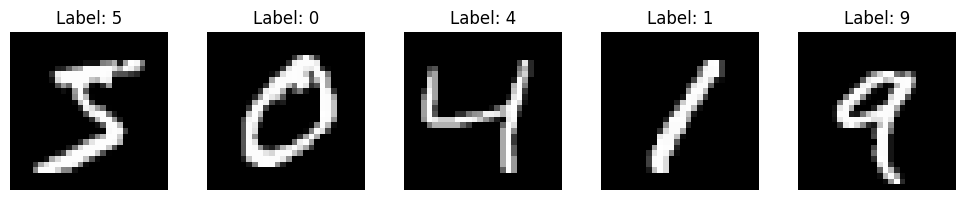

In [9]:
import matplotlib.pyplot as plt

# 先頭の5枚の画像を表示してみる
fig, axes = plt.subplots(1, 5, figsize=(10, 2))
for i in range(5):
    # 画素値データを28x28に整形して描画
    img = inputs[i].view(28, 28)
    axes[i].imshow(img, cmap="gray")
    axes[i].set_title(f"Label: {labels[i].item()}")
    axes[i].axis("off")

plt.tight_layout()
plt.show()

同じニューラルネットワークを CPU と GPU で10 epoch 学習します。1 epoch は、学習データ全体を1周することです。

進捗バーに表示する時間は学習ループの時間です。データの取得・最初の転送・テストは含めません。

In [10]:
from torch import nn
from tqdm import tqdm


def train_and_evaluate(device: str) -> None:
    """10 epoch の学習とテスト正解率の表示"""
    device = torch.device(device)
    torch.manual_seed(42)
    # 784個の画素値 → 中間層512個 → 数字0〜9の10クラス
    model = nn.Sequential(nn.Linear(784, 512), nn.ReLU(), nn.Linear(512, 128), nn.ReLU(), nn.Linear(128, 10)).to(device)
    # 画像と正解を先に移し、この転送を学習時間から外す
    x, y = inputs.to(device), labels.to(device)
    optimizer = torch.optim.SGD(model.parameters(), lr=0.1)
    criterion = nn.CrossEntropyLoss()
    batch_size = 1024
    synchronize(device)
    for epoch in tqdm(range(10), desc=f"{device} training", unit="epoch"):
        # 画像の番号をランダムに並べ替える（例：2, 0, 3, 1, ...）
        order = torch.randperm(len(x)).to(device)
        for offset in range(0, len(x), batch_size):
            # 並べ替えた番号から batch_size 枚分を取り出す
            indices = order[offset : offset + batch_size]
            optimizer.zero_grad()  # 前のバッチの勾配を消す
            loss = criterion(model(x[indices]), y[indices])
            loss.backward()  # 予測の誤差から勾配を計算する
            optimizer.step()  # 勾配に沿って重みを更新する
        synchronize(device)  # この epoch の計算完了を待って進捗を更新する

    model.eval()
    with torch.no_grad():
        predictions = model(test_inputs.to(device)).argmax(dim=1).cpu()
        accuracy = (predictions == test_labels).float().mean().item()
    print(f"{device} のテスト正解率: {accuracy:.1%}")


`device` を `"cpu"` / `"cuda"` に替えて、同じ関数を呼び出します。


In [11]:
train_and_evaluate("cpu")
if torch.cuda.is_available():
    train_and_evaluate("cuda")


cpu training: 100%|██████████| 10/10 [00:04<00:00,  2.49epoch/s]


cpu のテスト正解率: 92.5%


cuda training: 100%|██████████| 10/10 [00:00<00:00, 14.80epoch/s]

cuda のテスト正解率: 92.5%


CPU と GPU のテスト正解率と、進捗バーの経過時間を見比べてください。

## まとめ

- GPU と CPU の速度差は、処理の種類やデータ量によって変わります。
- CPU と GPU の間のデータ転送にも時間がかかります。

`matrix_sizes` や `batch_size` を変えて、時間差がどう変わるか調べてみるのも良いでしょう。